# Class imbalance: comparison of resampling strategies

The cleaned HCV data are heavily imbalanced (Healthy 533, Hepatitis 24,
Fibrosis 21, Cirrhosis 30). This notebook compares strategies for handling
the minority classes before the final machine-learning stage. It is a
strategy comparison, not the final model study: two reference classifiers
are used so that conclusions do not depend on a single algorithm.

To avoid leakage, the analysis starts from the **unimputed** data and every
preprocessing and resampling step is fitted inside each training fold.

In [1]:
# Libraries: standard library first, then third-party packages.
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from imblearn.combine import SMOTEENN, SMOTETomek
from imblearn.over_sampling import (
    ADASYN, SMOTE, BorderlineSMOTE, RandomOverSampler,
)
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import wilcoxon
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, make_scorer, precision_score, recall_score,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold, cross_val_predict, cross_validate,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Configuration

Constants are collected here. The cross-validation scheme is five-fold,
repeated five times, with a fixed seed so every strategy sees identical
splits.

In [2]:
# File location (relative, so the notebook runs from the project folder).
DATA_PATH = Path("hcvdat0.csv")

# One seed everywhere so the results can be reproduced exactly.
SEED = 42
ALPHA = 0.05

# Five-fold cross-validation repeated five times gives 25 test folds.
N_SPLITS = 5
N_REPEATS = 5

# Number of neighbours used when SMOTE-type methods invent new patients.
K_NEIGHBORS = 5

# Class order used in every table and chart.
CLASSES = ["Healthy", "Hepatitis", "Fibrosis", "Cirrhosis"]

# Predictors: 11 numeric measurements plus Sex.
NUMERIC = ["Age", "ALB", "ALP", "ALT", "AST", "BIL", "CHE", "CHOL",
           "CREA", "GGT", "PROT"]
CATEGORICAL = ["Sex"]

# The strategy that every other strategy is compared against.
BASELINE = "None (baseline)"

## Data loading and label cleaning

The labels are cleaned exactly as in `cleaning.ipynb`: the numeric prefix
is stripped, suspected blood donors are dropped and "Blood Donor" is renamed
"Healthy". Missing values are deliberately left in place; they are imputed
within each training fold later.

In [3]:
# Read the raw file and drop the unnamed patient index column.
raw_df = pd.read_csv(DATA_PATH)
df = raw_df.drop(columns=["Unnamed: 0"], errors="ignore").copy()

# Remove the "0=", "1=" ... prefixes so only the diagnosis name remains.
df["Category"] = df["Category"].str.replace(r"^[^=]*=", "", regex=True)

# Drop the suspected blood donors, whose true status is uncertain.
is_suspect = df["Category"].str.lower().str.contains("suspect")
df = df.loc[~is_suspect].reset_index(drop=True)

# Use the clearer label "Healthy" for ordinary blood donors.
df["Category"] = df["Category"].replace({"Blood Donor": "Healthy"})

# Separate predictors (X) from the diagnosis (y). No imputation here.
X = df[NUMERIC + CATEGORICAL]
y = df["Category"]

In [4]:
# Check the size, the amount of missing data and the class counts.
print(f"Rows: {len(df)}")
print(f"Missing predictor values: {int(X.isna().sum().sum())}")
display(y.value_counts().reindex(CLASSES).rename("Count").to_frame())

Rows: 608
Missing predictor values: 31


,Count
Category,
Healthy,533
Hepatitis,24
Fibrosis,21
Cirrhosis,30


## Cross-validation splits

The splits are generated once and reused for every strategy, so differences
between strategies are paired and not caused by different partitions.

In [5]:
# Create the 25 train/test splits once; every strategy reuses this list.
cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED
)
SPLITS = list(cv.split(X, y))

# Confirm that even the smallest class has enough training patients
# for the nearest-neighbour step of SMOTE (needs more than 5).
min_train = min(
    (y.iloc[train] == "Fibrosis").sum() for train, _ in SPLITS
)
print(f"Number of splits: {len(SPLITS)}")
print(f"Smallest Fibrosis count in a training fold: {min_train}")

Number of splits: 25
Smallest Fibrosis count in a training fold: 16


## Strategies and pipeline

Each pipeline imputes with the median and scales the numeric variables,
one-hot encodes Sex, then resamples and classifies. Because the pipeline
comes from `imblearn`, the sampler is applied to training folds only.
Strategies that reweight classes (`class_weight="balanced"`) use no
sampler. SMOTE-based samplers use five nearest neighbours; the smallest
training minority class is large enough for this.

In [6]:
# Each strategy is a pair: (sampler or None, use class weights?).
# Each pipeline receives its own fresh copy of the sampler.
smote = SMOTE(k_neighbors=K_NEIGHBORS, random_state=SEED)
STRATEGIES = {
    BASELINE: (None, False),
    "class_weight=balanced": (None, True),
    "RandomOverSampler": (RandomOverSampler(random_state=SEED), False),
    "SMOTE": (smote, False),
    "BorderlineSMOTE": (
        BorderlineSMOTE(k_neighbors=K_NEIGHBORS, random_state=SEED), False),
    "ADASYN": (ADASYN(n_neighbors=K_NEIGHBORS, random_state=SEED), False),
    "SMOTETomek": (SMOTETomek(smote=smote, random_state=SEED), False),
    "SMOTEENN": (SMOTEENN(smote=smote, random_state=SEED), False),
    "RandomUnderSampler": (RandomUnderSampler(random_state=SEED), False),
}
MODELS = ["Logistic regression", "Random forest"]

In [7]:
# Preprocessing is identical for all runs: median-impute and scale the
# numbers, one-hot encode Sex. It lives inside the pipeline, so it is
# learned from training folds only (no leakage from the test fold).
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])


def build_pipeline(model_name, strategy):
    """Preprocessing, optional sampler, then the chosen classifier."""
    sampler, balanced = STRATEGIES[strategy]
    # "balanced" makes rare classes count more during model fitting.
    weight = "balanced" if balanced else None
    if model_name == "Logistic regression":
        classifier = LogisticRegression(
            max_iter=5000, class_weight=weight, random_state=SEED)
    else:
        classifier = RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight=weight,
            random_state=SEED, n_jobs=-1)
    # The sampler step is only added when the strategy has one. A fresh
    # copy is used each time so no state carries over between runs.
    steps = [("prep", preprocess)]
    if sampler is not None:
        steps.append(("sampler", clone(sampler)))
    steps.append(("clf", classifier))
    return Pipeline(steps)

## Metrics and evaluation helper

Macro F1 and balanced accuracy treat all classes equally, which is the
relevant view when minority classes matter clinically. Per-class recall
shows where each strategy gains or loses. Errors are raised, not
swallowed, so any failing sampler (for example ADASYN on a fold) would be
visible.

In [8]:
# Overall scores that give every class the same weight.
SCORING = {
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "macro_precision": make_scorer(
        precision_score, average="macro", zero_division=0),
}

# One recall score per class, so we can see who gains and who loses.
for label in CLASSES:
    SCORING[f"recall_{label}"] = make_scorer(
        recall_score, labels=[label], average="macro", zero_division=0)

In [9]:
def evaluate_strategy(model_name, strategy):
    """Cross-validate one model and strategy; one row per fold."""
    pipeline = build_pipeline(model_name, strategy)
    # error_score="raise" stops the run if any fold fails, so a failure
    # (for example in ADASYN) can never be skipped without notice.
    scores = cross_validate(
        pipeline, X, y, cv=SPLITS, scoring=SCORING, error_score="raise")
    # Keep only the test scores and label them with model and strategy.
    table = pd.DataFrame({
        name[len("test_"):]: values
        for name, values in scores.items() if name.startswith("test_")
    })
    table.insert(0, "fold", range(len(table)))
    table.insert(0, "strategy", strategy)
    table.insert(0, "model", model_name)
    return table

## Running all strategies

Every model and strategy pair is evaluated on the same 25 splits.

In [10]:
# Some samplers print harmless warnings; hide them to keep output readable.
warnings.filterwarnings("ignore", category=UserWarning)

# Evaluate every model with every strategy and stack the fold results.
frames = []
for model_name in MODELS:
    for strategy in STRATEGIES:
        frames.append(evaluate_strategy(model_name, strategy))
results = pd.concat(frames, ignore_index=True)
print(f"Fold-level rows: {len(results)}")

Fold-level rows: 450


## Mean and standard deviation per model and strategy

Values are the mean (SD) over the 25 test folds.

In [11]:
# Average each metric over the 25 folds, and measure its spread.
METRICS = ["macro_f1", "balanced_accuracy", "macro_precision"]
METRICS += [f"recall_{c}" for c in CLASSES]
grouped = results.groupby(["model", "strategy"], sort=False)[METRICS]
mean_table = grouped.mean()
sd_table = grouped.std()

# Combine into "mean (SD)" text for easy reading, one table per model.
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
formatted = (mean_table.round(3).astype(str) + " ("
             + sd_table.round(3).astype(str) + ")")
for model_name in MODELS:
    print(model_name)
    display(formatted.loc[model_name])

Logistic regression


,macro_f1,balanced_accuracy,macro_precision,recall_Healthy,recall_Hepatitis,recall_Fibrosis,recall_Cirrhosis
strategy,,,,,,,
None (baseline),0.653 (0.082),0.625 (0.081),0.75 (0.116),0.995 (0.005),0.4 (0.199),0.366 (0.184),0.74 (0.205)
class_weight=balanced,0.602 (0.062),0.667 (0.073),0.584 (0.071),0.927 (0.028),0.578 (0.235),0.478 (0.168),0.687 (0.227)
RandomOverSampler,0.588 (0.057),0.649 (0.072),0.571 (0.068),0.923 (0.032),0.524 (0.249),0.45 (0.177),0.7 (0.198)
SMOTE,0.608 (0.055),0.66 (0.065),0.597 (0.064),0.935 (0.031),0.534 (0.22),0.458 (0.222),0.713 (0.19)
BorderlineSMOTE,0.617 (0.063),0.659 (0.076),0.622 (0.073),0.952 (0.02),0.546 (0.217),0.458 (0.23),0.68 (0.225)
ADASYN,0.596 (0.065),0.654 (0.072),0.577 (0.077),0.935 (0.026),0.578 (0.227),0.398 (0.225),0.707 (0.188)
SMOTETomek,0.608 (0.055),0.66 (0.065),0.597 (0.064),0.935 (0.031),0.534 (0.22),0.458 (0.222),0.713 (0.19)
SMOTEENN,0.593 (0.069),0.654 (0.075),0.576 (0.078),0.928 (0.032),0.542 (0.226),0.44 (0.246),0.707 (0.188)
RandomUnderSampler,0.608 (0.047),0.701 (0.056),0.587 (0.048),0.894 (0.041),0.604 (0.23),0.606 (0.176),0.7 (0.22)


Random forest


,macro_f1,balanced_accuracy,macro_precision,recall_Healthy,recall_Hepatitis,recall_Fibrosis,recall_Cirrhosis
strategy,,,,,,,
None (baseline),0.59 (0.091),0.566 (0.085),0.657 (0.13),0.996 (0.005),0.258 (0.229),0.258 (0.187),0.753 (0.199)
class_weight=balanced,0.644 (0.097),0.604 (0.099),0.754 (0.119),1.0 (0.002),0.348 (0.216),0.348 (0.232),0.72 (0.197)
RandomOverSampler,0.657 (0.097),0.629 (0.103),0.75 (0.118),0.997 (0.005),0.442 (0.25),0.358 (0.244),0.72 (0.185)
SMOTE,0.677 (0.082),0.68 (0.078),0.718 (0.12),0.99 (0.011),0.558 (0.276),0.344 (0.237),0.827 (0.148)
BorderlineSMOTE,0.665 (0.077),0.654 (0.083),0.731 (0.104),0.993 (0.008),0.458 (0.24),0.364 (0.216),0.8 (0.173)
ADASYN,0.668 (0.08),0.674 (0.075),0.712 (0.12),0.99 (0.012),0.556 (0.287),0.308 (0.223),0.84 (0.14)
SMOTETomek,0.679 (0.08),0.683 (0.077),0.719 (0.119),0.99 (0.011),0.566 (0.286),0.344 (0.237),0.833 (0.144)
SMOTEENN,0.682 (0.065),0.689 (0.059),0.721 (0.108),0.985 (0.013),0.574 (0.259),0.366 (0.207),0.833 (0.144)
RandomUnderSampler,0.595 (0.073),0.67 (0.088),0.578 (0.071),0.914 (0.029),0.502 (0.27),0.53 (0.267),0.733 (0.18)


## Ranking of strategies

Strategies are ranked within each model by mean macro F1 and by mean
balanced accuracy.

In [12]:
# Sort the strategies from best to worst within each model, once per
# headline metric, and number them.
for metric in ["macro_f1", "balanced_accuracy"]:
    ranking = (
        mean_table[metric].round(3).rename(metric).reset_index()
        .sort_values(["model", metric], ascending=[True, False])
    )
    ranking["rank"] = ranking.groupby("model").cumcount() + 1
    print(f"Ranking by {metric}")
    display(ranking.set_index(["model", "rank"]))

Ranking by macro_f1


strategy  macro_f1
model               rank                                 
Logistic regression 1           None (baseline)     0.653
                    2           BorderlineSMOTE     0.617
                    3                     SMOTE     0.608
                    4                SMOTETomek     0.608
                    5        RandomUnderSampler     0.608
                    6     class_weight=balanced     0.602
                    7                    ADASYN     0.596
                    8                  SMOTEENN     0.593
                    9         RandomOverSampler     0.588
Random forest       1                  SMOTEENN     0.682
                    2                SMOTETomek     0.679
                    3                     SMOTE     0.677
                    4                    ADASYN     0.668
                    5           BorderlineSMOTE     0.665
                    6         RandomOverSampler     0.657
                    7     class_weight=balanced     0.644
                    8        RandomUnderSampler     0.595
                    9           None (baseline)     0.590

Ranking by balanced_accuracy


strategy  balanced_accuracy
model               rank                                          
Logistic regression 1        RandomUnderSampler              0.701
                    2     class_weight=balanced              0.667
                    3                     SMOTE              0.660
                    4                SMOTETomek              0.660
                    5           BorderlineSMOTE              0.659
                    6                    ADASYN              0.654
                    7                  SMOTEENN              0.654
                    8         RandomOverSampler              0.649
                    9           None (baseline)              0.625
Random forest       1                  SMOTEENN              0.689
                    2                SMOTETomek              0.683
                    3                     SMOTE              0.680
                    4                    ADASYN              0.674
                    5        RandomUnderSampler              0.670
                    6           BorderlineSMOTE              0.654
                    7         RandomOverSampler              0.629
                    8     class_weight=balanced              0.604
                    9           None (baseline)              0.566

## Paired differences against the baseline

For each strategy the per-fold difference from the baseline is computed on
identical splits. The table gives the mean difference and a Wilcoxon
signed-rank p-value, Bonferroni-adjusted across the eight strategies per
model and metric.

**Caveat.** Cross-validation folds share training data and are not
independent, so these p-values are indicative only; they should be read as
a rough guide to consistency, not as formal evidence.

In [13]:
# Compare each strategy with the baseline, fold by fold, because the
# splits are identical. A positive difference means better than baseline.
rows = []
others = [name for name in STRATEGIES if name != BASELINE]
for model_name in MODELS:
    model_rows = results[results["model"] == model_name]
    for metric in ["macro_f1", "balanced_accuracy"]:
        base = model_rows[model_rows["strategy"] == BASELINE][metric]
        for strategy in others:
            scores = model_rows[model_rows["strategy"] == strategy][metric]
            diff = scores.to_numpy() - base.to_numpy()

            # Wilcoxon cannot run when all differences are zero; that
            # means no difference at all, so the p-value is set to 1.
            if np.all(diff == 0):
                p_value = 1.0
            else:
                p_value = wilcoxon(diff).pvalue
            rows.append({"model": model_name, "metric": metric,
                         "strategy": strategy, "mean_diff": diff.mean(),
                         "p_raw": p_value})
paired = pd.DataFrame(rows)

# Bonferroni: multiply by the number of strategies tested (8), cap at 1.
paired["p_adj"] = (paired["p_raw"] * len(others)).clip(upper=1)
paired["significant"] = paired["p_adj"] < ALPHA
paired[["mean_diff", "p_raw", "p_adj"]] = paired[
    ["mean_diff", "p_raw", "p_adj"]].round(4)
display(paired)

,model,metric,strategy,mean_diff,p_raw,p_adj,significant
0,Logistic regression,macro_f1,class_weight=balanced,-0.0517,0.0074,0.0590,False
1,Logistic regression,macro_f1,RandomOverSampler,-0.0652,0.0007,0.0057,True
2,Logistic regression,macro_f1,SMOTE,-0.0451,0.0393,0.3147,False
3,Logistic regression,macro_f1,BorderlineSMOTE,-0.0359,0.0422,0.3372,False
4,Logistic regression,macro_f1,ADASYN,-0.0570,0.0046,0.0368,True
5,Logistic regression,macro_f1,SMOTETomek,-0.0451,0.0393,0.3147,False
6,Logistic regression,macro_f1,SMOTEENN,-0.0600,0.0160,0.1278,False
7,Logistic regression,macro_f1,RandomUnderSampler,-0.0450,0.0125,0.0997,False
8,Logistic regression,balanced_accuracy,class_weight=balanced,0.0421,0.0105,0.0841,False
9,Logistic regression,balanced_accuracy,RandomOverSampler,0.0239,0.0588,0.4700,False


## Per-class recall by strategy

One grouped bar chart per model shows which classes each strategy helps
or harms.

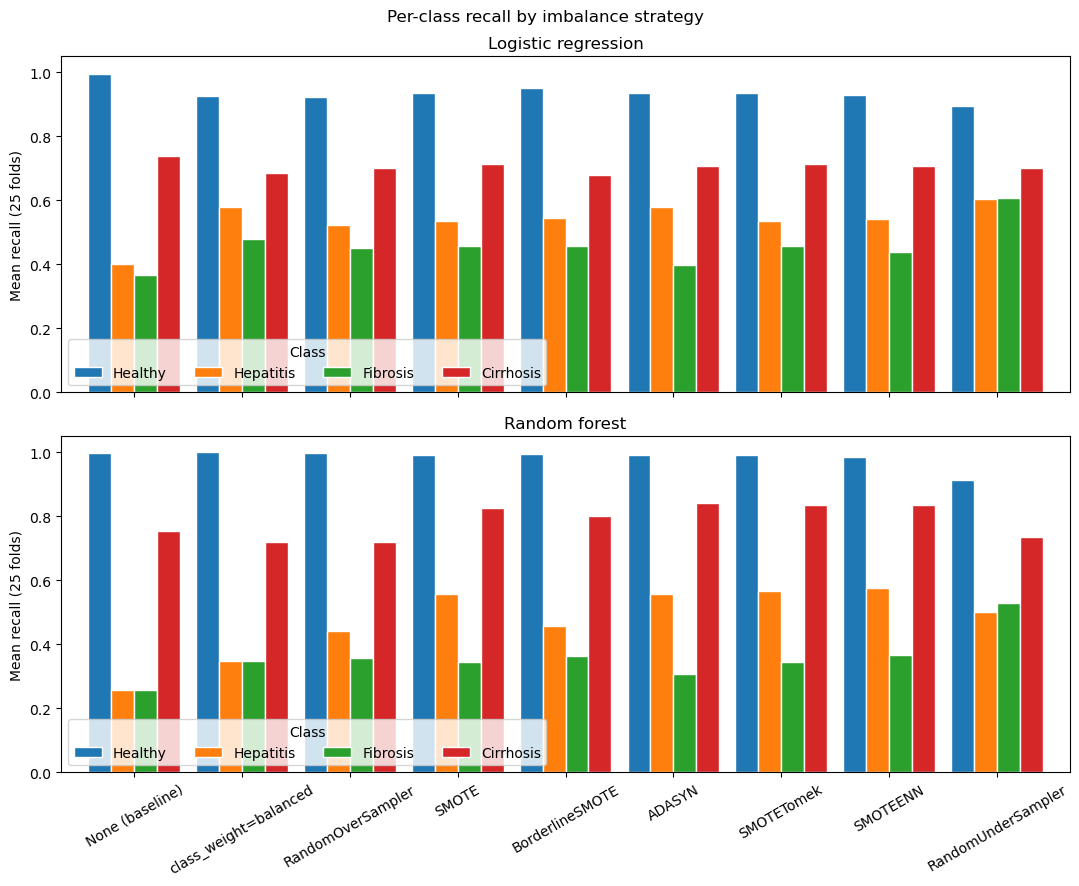

In [14]:
# One panel per model; bars are grouped by strategy, coloured by class.
fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)
for ax, model_name in zip(axes, MODELS):
    recall = mean_table.loc[model_name][[f"recall_{c}" for c in CLASSES]]
    recall.columns = CLASSES
    recall.plot.bar(ax=ax, width=0.85, edgecolor="white")

    # Labels and a common 0-1 scale make the two panels comparable.
    ax.set_title(model_name)
    ax.set_ylabel("Mean recall (25 folds)")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Class", ncol=4, loc="lower left")
fig.suptitle("Per-class recall by imbalance strategy")
fig.tight_layout()
plt.show()

## Pooled out-of-fold confusion matrices

For the top two strategies per model (by mean macro F1), predictions come
from the first repeat's five folds only, so each patient is predicted
exactly once.

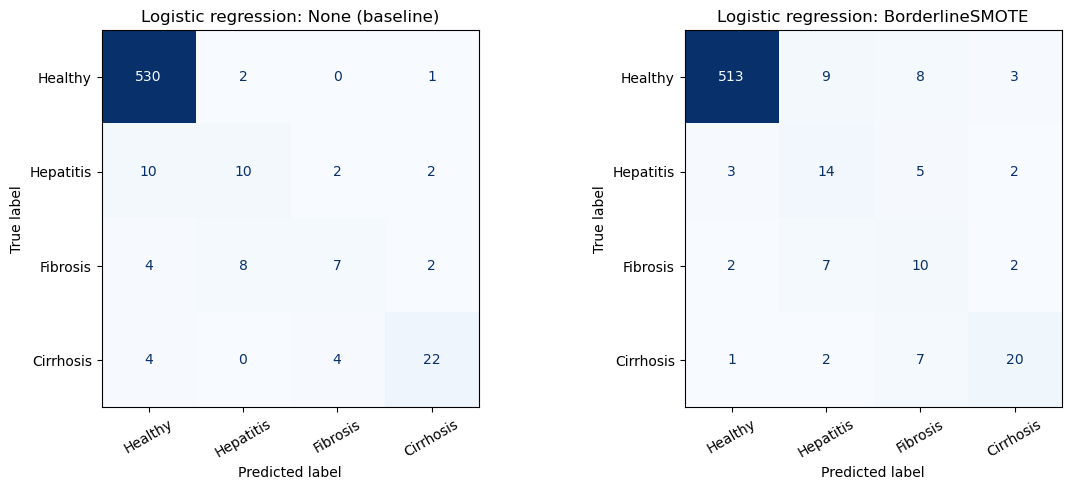

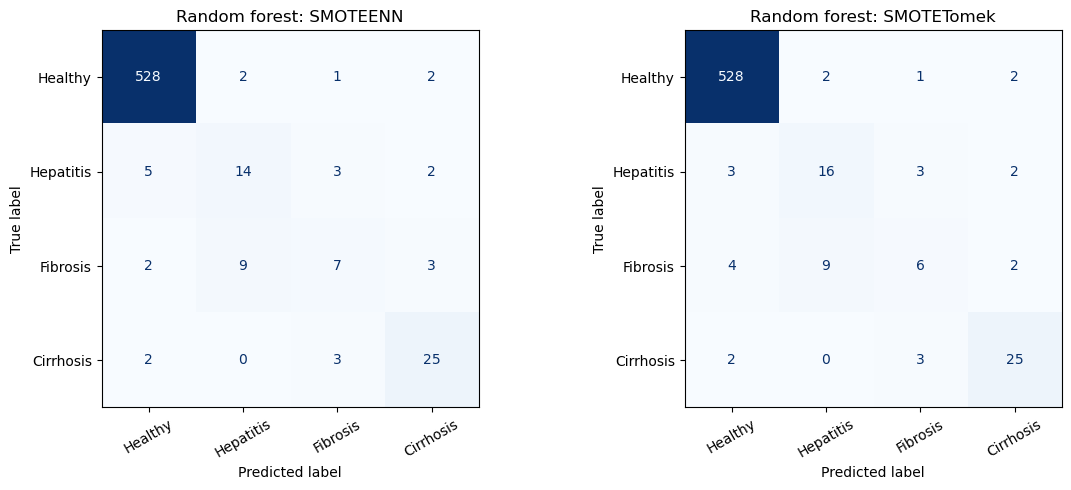

In [15]:
# For each model, pick the two strategies with the highest macro F1.
for model_name in MODELS:
    top_two = mean_table.loc[model_name]["macro_f1"].nlargest(2).index
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, strategy in zip(axes, top_two):
        # Use only the first repeat (the first 5 splits) so that every
        # patient appears in exactly one test fold and is predicted once.
        pipeline = build_pipeline(model_name, strategy)
        predicted = cross_val_predict(pipeline, X, y, cv=SPLITS[:N_SPLITS])

        # Draw the confusion matrix: rows are true, columns predicted.
        ConfusionMatrixDisplay.from_predictions(
            y, predicted, labels=CLASSES, ax=ax, colorbar=False,
            cmap="Blues")
        ax.set_title(f"{model_name}: {strategy}")
        ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    plt.show()

## Findings

Findings are written in `findings.md`, using the numbers printed above.